# 03 · Preprocesamiento — AccessGuard AI

**Hito H1 · Clase 2.** De las decisiones del EDA a **código reproducible con pruebas**: limpieza, partición por gerente, imputación,
codificación de categóricas (roles / recursos / gerentes), escalado de lo numérico y selección justificada de variables.

Este notebook **solo orquesta**: la lógica vive en `src/accessguard/` (`data/cleaning.py`, `data/split.py`, `features.py`) y se prueba con `pytest`.
Reglas: `Data/train.csv` y `Data/test.csv` **no se modifican**; todo lo que se genera va a `Data/processed/`; el conjunto de reserva **no se usa para decidir nada**.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]   # permite importar config/ y src/accessguard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import settings as S

pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, GRAY = "#2A6FBB", "#D9622B", "#8A8F98"   # aprobado / denegado / neutro

import json
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from accessguard.data import REDUNDANT_COLUMNS, check_schema, drop_redundant, find_redundant_pairs, split_by_group
from accessguard.features import HIGH_CARD, LOW_CARD, build_preprocessor
from accessguard.stats import cramers_v

S.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train_raw = pd.read_csv(S.TRAIN_PATH)
test_raw = pd.read_csv(S.TEST_PATH)
print("Esquema train — columnas faltantes:", check_schema(train_raw, S.FEATURES + [S.TARGET]) or "ninguna")
print("Esquema test  — columnas faltantes:", check_schema(test_raw, S.FEATURES + [S.TEST_ID_COL]) or "ninguna")

Esquema train — columnas faltantes: ninguna
Esquema test  — columnas faltantes: ninguna


## 1. Limpieza (reglas del EDA)

Decisión 4 del EDA: `ROLE_TITLE` y `ROLE_CODE` son equivalentes uno a uno → se elimina `ROLE_CODE`.
La función **comprueba** la equivalencia en los datos en lugar de asumirla.

In [2]:
pairs = find_redundant_pairs(train_raw, S.FEATURES)
print("Pares de columnas equivalentes (uno a uno) en train:", pairs)
assert ("ROLE_TITLE", "ROLE_CODE") in pairs and not set(find_redundant_pairs(test_raw, ["ROLE_TITLE", "ROLE_CODE"])) ^ {("ROLE_TITLE", "ROLE_CODE")}

train_c = drop_redundant(train_raw)
test_c = drop_redundant(test_raw)
FEATS = [c for c in S.FEATURES if c not in REDUNDANT_COLUMNS]
print(f"\nColumnas eliminadas: {REDUNDANT_COLUMNS}  →  {len(FEATS)} variables de entrada: {FEATS}")
print("Datos personales a eliminar: ninguno (el dataset solo trae códigos numéricos anónimos).")

Pares de columnas equivalentes (uno a uno) en train: [('ROLE_TITLE', 'ROLE_CODE')]

Columnas eliminadas: ['ROLE_CODE']  →  8 variables de entrada: ['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_1', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC', 'ROLE_FAMILY']
Datos personales a eliminar: ninguno (el dataset solo trae códigos numéricos anónimos).


## 2. Partición por la unidad correcta (gerente) y reserva cerrada

- **Reserva cerrada (20 %)**: se aparta ahora y **no se mira** hasta la etapa de validación final.
- Dentro del 80 % restante se hace una segunda partición por gerente (entrenamiento / validación) que sirve para **decidir** (selección de variables, etc.).
- Ambas son **estratificadas por `ACTION`** (mantienen el ~5,8 % de denegadas) y **por grupo** (`MGR_ID`).

In [3]:
fit_part, holdout = split_by_group(train_c, S.GROUP_COL, S.TARGET, S.HOLDOUT_FRACTION, S.SEED)
sub_train, valid = split_by_group(fit_part, S.GROUP_COL, S.TARGET, 0.2, S.SEED)

summary = pd.DataFrame({
    "filas": [len(sub_train), len(valid), len(holdout)],
    "% denegadas": [100 * (1 - d[S.TARGET].mean()) for d in (sub_train, valid, holdout)],
    "gerentes": [d[S.GROUP_COL].nunique() for d in (sub_train, valid, holdout)],
}, index=["entrenamiento", "validación", "reserva (cerrada)"])
display(summary.round(2))

# Comprobaciones (las mismas que cubre tests/test_split.py)
assert set(sub_train[S.GROUP_COL]).isdisjoint(valid[S.GROUP_COL])
assert set(fit_part[S.GROUP_COL]).isdisjoint(holdout[S.GROUP_COL])
assert len(sub_train) + len(valid) + len(holdout) == len(train_c)
print("✔ Ningún gerente aparece en dos particiones y no se perdió ninguna fila.")

,filas,% denegadas,gerentes
entrenamiento,20972,5.79,2686
validación,5243,5.78,674
reserva (cerrada),6554,5.78,883


✔ Ningún gerente aparece en dos particiones y no se perdió ninguna fila.


### 2.1 Por qué por gerente: la fuga, medida

Mismo modelo y mismos datos; solo cambia **cómo se parte**. (Se usa únicamente el 80 % de entrenamiento, no la reserva.)

In [4]:
def make_model(features, use_freq=True, C=1.0):
    low = [c for c in features if c in LOW_CARD]
    high = [c for c in features if c in HIGH_CARD]
    pre = build_preprocessor(low, high, seed=S.SEED, use_freq=use_freq)
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=2000))])

def evaluate(train_df, valid_df, features, **kw):
    m = make_model(features, **kw).fit(train_df[features], train_df[S.TARGET])
    p = m.predict_proba(valid_df[features])[:, 1]                    # P(aprobar)
    y = valid_df[S.TARGET].to_numpy()
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC (denegar)": average_precision_score(1 - y, 1 - p)}

row_tr, row_va = train_test_split(fit_part, test_size=0.2, stratify=fit_part[S.TARGET], random_state=S.SEED)
res = pd.DataFrame({
    "Por FILA (mal)": evaluate(row_tr, row_va, FEATS),
    "Por GERENTE (bien)": evaluate(sub_train, valid, FEATS),
}).T
res["gerentes compartidos"] = [len(set(row_tr[S.GROUP_COL]) & set(row_va[S.GROUP_COL])), len(set(sub_train[S.GROUP_COL]) & set(valid[S.GROUP_COL]))]
display(res.round(3))

,ROC-AUC,PR-AUC (denegar),gerentes compartidos
Por FILA (mal),0.816,0.415,1866
Por GERENTE (bien),0.710,0.162,0


**Lectura.** Con partición por fila, entrenamiento y validación comparten 1.866 gerentes: ROC-AUC ≈ 0,82 y PR-AUC(denegar) ≈ 0,42. Con partición por gerente (0 compartidos) el
mismo modelo baja a ROC-AUC ≈ 0,71 y PR-AUC ≈ 0,16: **más de la mitad del PR-AUC "aparente" era memorizar al gerente**. Esa diferencia es la fuga.
Para una decisión sobre gerentes nuevos, la cifra honesta es la de abajo. Nota: en `test.csv` el 97,2 % de las filas ya tiene un gerente conocido, de modo que la cifra "por gerente" es **conservadora**
(subestima el desempeño en ese escenario) y la "por fila" lo sobrestima: la realidad queda en medio, y por eso se reporta la conservadora.

## 3. Valores faltantes e imputación

El EDA midió **0 vacíos** en train y test, así que hoy no se imputa nada con datos reales. Aun así el `Pipeline` incluye un imputador de seguridad
(`SimpleImputer(constant → "DESCONOCIDO")`): una solicitud nueva en producción puede llegar con un campo vacío, y "desconocido" es una categoría honesta
(no una media inventada). Se comprueba que no rompe nada:

In [5]:
print("Vacíos en train:", int(train_c[FEATS].isna().sum().sum()), "| en test:", int(test_c[FEATS].isna().sum().sum()))

model_all = make_model(FEATS).fit(sub_train[FEATS], sub_train[S.TARGET])
probe = valid[FEATS].head(5).copy()
probe.iloc[0, :] = np.nan                    # fila completamente vacía
probe.loc[probe.index[1], "MGR_ID"] = 99_999_999   # gerente nunca visto
probe.loc[probe.index[2], "RESOURCE"] = -1         # recurso inexistente
p = model_all.predict_proba(probe)[:, 1]
print("Probabilidades de 'aprobar' con entradas anómalas:", p.round(3), "→ finitas:", bool(np.isfinite(p).all()))

Vacíos en train: 0 | en test: 0


Probabilidades de 'aprobar' con entradas anómalas: [0.981 0.98  0.974 0.984 0.999] → finitas: True


## 4. Codificación y escalado

| Grupo | Columnas | Técnica | Por qué |
|---|---|---|---|
| Baja/media cardinalidad (67–449 categorías) | `ROLE_ROLLUP_1`, `ROLE_ROLLUP_2`, `ROLE_DEPTNAME`, `ROLE_TITLE`, `ROLE_FAMILY` | **One-hot** con `min_frequency=10` (las raras se agrupan en "infrecuente"; las nuevas caen ahí) | Manejable en número de columnas y sin orden artificial |
| Alta cardinalidad (2.358–7.518 categorías) | `RESOURCE`, `MGR_ID`, `ROLE_FAMILY_DESC` | **Target encoding** (tasa de aprobación suavizada, con validación cruzada interna de 5 pliegues) → **escalado** | One-hot daría >14.000 columnas casi vacías; el CV interno evita que una fila vea su propia etiqueta |
| Numéricas derivadas | `log(1+frecuencia)` de esas 3 columnas | **Codificación de frecuencia** → **escalado** (`StandardScaler`) | Captura "novedad" del recurso/gerente; los conteos son sesgados y de otra escala |

Todo vive dentro de un `Pipeline` **ajustado solo con el entrenamiento** (`fit` sobre `sub_train`), para no filtrar información de validación.

In [6]:
pre = build_preprocessor([c for c in LOW_CARD if c in FEATS], [c for c in HIGH_CARD if c in FEATS], seed=S.SEED)
Xtr = pre.fit_transform(sub_train[FEATS], sub_train[S.TARGET])
Xva = pre.transform(valid[FEATS])
Xte = pre.transform(test_c[FEATS])
names = pre.get_feature_names_out()

blocks = pd.Series([n.split("__")[0] for n in names]).value_counts()
print(f"Matriz de entrenamiento: {Xtr.shape[0]:,} filas x {Xtr.shape[1]:,} columnas  (validación {Xva.shape}, test.csv {Xte.shape})")
print("Columnas por bloque:\n", blocks.to_string())

dense = lambda m: m.toarray() if hasattr(m, "toarray") else np.asarray(m)
sc_idx = [i for i, n in enumerate(names) if n.startswith(("target__", "freq__"))]
scaled = dense(Xtr)[:, sc_idx]
print(f"\nColumnas escaladas ({len(sc_idx)}): media ≈ {scaled.mean(axis=0).round(3)}  desv. ≈ {scaled.std(axis=0).round(3)}")
print("Sin NaN/inf en train, validación ni test.csv:", all(np.isfinite(dense(m)).all() for m in (Xtr, Xva, Xte)))

Matriz de entrenamiento: 20,972 filas x 741 columnas  (validación (5243, 741), test.csv (58921, 741))
Columnas por bloque:
 onehot    735
target      3
freq        3

Columnas escaladas (6): media ≈ [ 0. -0.  0. -0.  0.  0.]  desv. ≈ [1. 1. 1. 1. 1. 1.]
Sin NaN/inf en train, validación ni test.csv: True


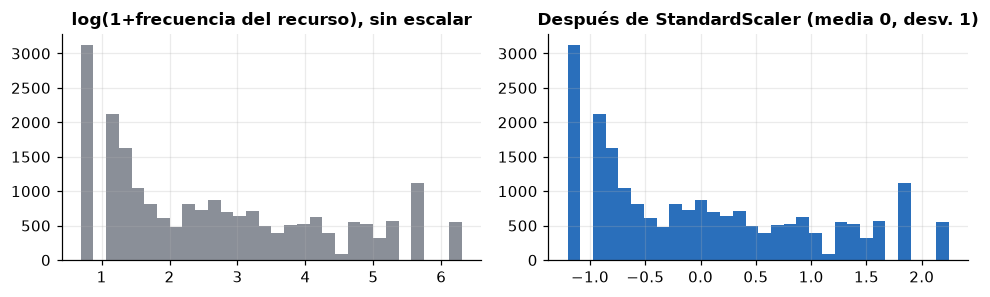

In [7]:
# Las dos columnas escaladas de RESOURCE: tasa de aprobación codificada y frecuencia (antes y después de escalar)
fe = pd.DataFrame({n: dense(Xtr)[:, i] for i, n in enumerate(names) if n in {"target__RESOURCE", "freq__RESOURCE__logfreq"}})
raw_cnt = np.log1p(sub_train["RESOURCE"].map(sub_train["RESOURCE"].value_counts()))
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].hist(raw_cnt, bins=30, color=GRAY); axes[0].set_title("log(1+frecuencia del recurso), sin escalar")
axes[1].hist(fe["freq__RESOURCE__logfreq"], bins=30, color=BLUE); axes[1].set_title("Después de StandardScaler (media 0, desv. 1)")
plt.tight_layout(); plt.show()

## 5. Selección de variables (feature selection) — con criterio, sin tocar la reserva

La selección se decide **solo con el 80 % de entrenamiento**, usando validación cruzada de 5 pliegues **por gerente** (la reserva no interviene). Tres criterios, de lo más a lo menos objetivo:

1. **Redundancia** (ya aplicada): `ROLE_CODE` ≡ `ROLE_TITLE`.
2. **Asociación con el objetivo** (V de Cramér en entrenamiento): orientativa; se infla con alta cardinalidad.
3. **Ablación (quitar una variable y medir)**: criterio decisivo. Si quitar la variable no empeora el desempeño de validación más allá de una tolerancia, **no se justifica conservarla**.

In [8]:
assoc = pd.Series({c: cramers_v(sub_train[c], sub_train[S.TARGET]) for c in FEATS}, name="V de Cramér con ACTION").sort_values(ascending=False)
display(assoc.round(3).to_frame())

,V de Cramér con ACTION
MGR_ID,0.452
RESOURCE,0.342
ROLE_FAMILY_DESC,0.315
ROLE_DEPTNAME,0.274
ROLE_ROLLUP_2,0.190
ROLE_TITLE,0.189
ROLE_ROLLUP_1,0.156
ROLE_FAMILY,0.127


,ROC-AUC,PR-AUC (denegar),Δ ROC-AUC medio,Δ ROC-AUC desv. entre pliegues,Δ PR-AUC medio
TODAS (referencia),0.7021,0.1580,0.0000,0.0000,0.0000
sin RESOURCE,0.6860,0.1509,-0.0161,0.0069,-0.0071
sin MGR_ID,0.7000,0.1668,-0.0021,0.0082,0.0087
sin ROLE_ROLLUP_1,0.7029,0.1577,0.0008,0.0013,-0.0004
sin ROLE_ROLLUP_2,0.6988,0.1449,-0.0033,0.0091,-0.0131
sin ROLE_DEPTNAME,0.6841,0.1407,-0.0180,0.0136,-0.0174
sin ROLE_TITLE,0.6892,0.1486,-0.0129,0.0071,-0.0094
sin ROLE_FAMILY_DESC,0.6925,0.1424,-0.0096,0.0106,-0.0157
sin ROLE_FAMILY,0.7008,0.1587,-0.0013,0.0032,0.0007
sin variables de frecuencia,0.6933,0.1531,-0.0088,0.0053,-0.0049


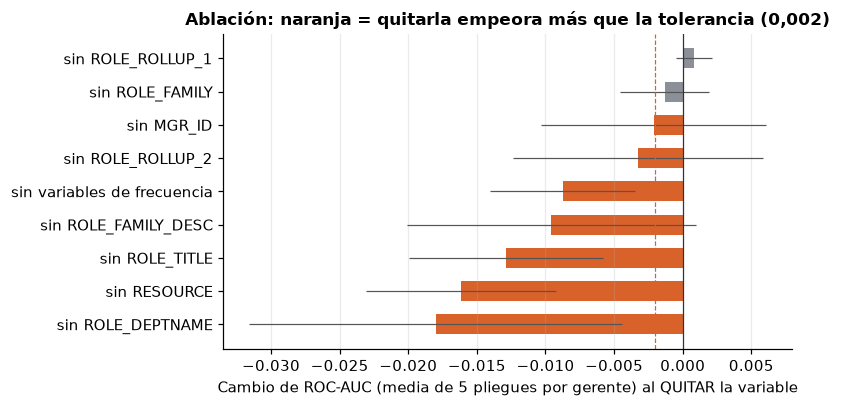

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=S.SEED).split(fit_part, fit_part[S.TARGET], groups=fit_part[S.GROUP_COL]))

def cv_scores(features, **kw):
    return pd.DataFrame([evaluate(fit_part.iloc[a], fit_part.iloc[b], features, **kw) for a, b in folds])   # una fila por pliegue

variants = {"TODAS (referencia)": cv_scores(FEATS)}
for c in FEATS:
    variants[f"sin {c}"] = cv_scores([f for f in FEATS if f != c])
variants["sin variables de frecuencia"] = cv_scores(FEATS, use_freq=False)

ref = variants["TODAS (referencia)"]
abl = pd.DataFrame({
    "ROC-AUC": {k: v["ROC-AUC"].mean() for k, v in variants.items()},
    "PR-AUC (denegar)": {k: v["PR-AUC (denegar)"].mean() for k, v in variants.items()},
    "Δ ROC-AUC medio": {k: (v["ROC-AUC"] - ref["ROC-AUC"]).mean() for k, v in variants.items()},
    "Δ ROC-AUC desv. entre pliegues": {k: (v["ROC-AUC"] - ref["ROC-AUC"]).std() for k, v in variants.items()},
    "Δ PR-AUC medio": {k: (v["PR-AUC (denegar)"] - ref["PR-AUC (denegar)"]).mean() for k, v in variants.items()},
})
base_metrics = {"ROC-AUC": abl.loc["TODAS (referencia)", "ROC-AUC"], "PR-AUC (denegar)": abl.loc["TODAS (referencia)", "PR-AUC (denegar)"]}
display(abl.round(4))

fig, ax = plt.subplots(figsize=(7.4, 3.8))
d = abl.drop(index="TODAS (referencia)").sort_values("Δ ROC-AUC medio")
ax.barh(d.index, d["Δ ROC-AUC medio"], xerr=d["Δ ROC-AUC desv. entre pliegues"], height=0.6,
        color=[ORANGE if v < -0.002 else GRAY for v in d["Δ ROC-AUC medio"]], error_kw={"lw": 0.8, "ecolor": "#555"})
ax.axvline(0, color="#333", lw=0.8); ax.axvline(-0.002, color=ORANGE, ls="--", lw=0.8)
ax.set_xlabel("Cambio de ROC-AUC (media de 5 pliegues por gerente) al QUITAR la variable"); ax.grid(axis="y", visible=False)
ax.set_title("Ablación: naranja = quitarla empeora más que la tolerancia (0,002)")
plt.tight_layout(); plt.show()

In [10]:
TOL = 0.002   # tolerancia: una variable se conserva si quitarla empeora el ROC-AUC medio de validación en más de 0,002
drop_gain = abl.drop(index=["TODAS (referencia)", "sin variables de frecuencia"])["Δ ROC-AUC medio"]
keep = [c for c in FEATS if drop_gain[f"sin {c}"] < -TOL]
dropped = [c for c in FEATS if c not in keep]
SELECTED = keep
print("Variables conservadas :", SELECTED)
print("Variables descartadas :", dropped, f"(quitarlas no empeora más de {TOL} de ROC-AUC)")
sel_cv = cv_scores(SELECTED)
sel_metrics = {"ROC-AUC": sel_cv["ROC-AUC"].mean(), "PR-AUC (denegar)": sel_cv["PR-AUC (denegar)"].mean()}
print(); print(f"CV por gerente con TODAS     : ROC-AUC {base_metrics['ROC-AUC']:.4f} | PR-AUC(denegar) {base_metrics['PR-AUC (denegar)']:.4f}")
print(f"CV por gerente con SELECCIÓN : ROC-AUC {sel_metrics['ROC-AUC']:.4f} | PR-AUC(denegar) {sel_metrics['PR-AUC (denegar)']:.4f}")

Variables conservadas : ['RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC']
Variables descartadas : ['ROLE_ROLLUP_1', 'ROLE_FAMILY'] (quitarlas no empeora más de 0.002 de ROC-AUC)



CV por gerente con TODAS     : ROC-AUC 0.7021 | PR-AUC(denegar) 0.1580
CV por gerente con SELECCIÓN : ROC-AUC 0.7021 | PR-AUC(denegar) 0.1597


**Cómo leer esto (y sus límites).**

- Se descartan `ROLE_ROLLUP_1` y `ROLE_FAMILY`: quitarlas no cambia el desempeño (Δ ≈ +0,0008 y −0,0013, dentro del ruido entre pliegues). Es coherente con el EDA: son **jerárquicamente redundantes**
  (`ROLE_ROLLUP_2` determina a `ROLE_ROLLUP_1` en 98 % y `ROLE_TITLE` determina a `ROLE_FAMILY` en 100 %).
- Las que más duele perder son `ROLE_DEPTNAME`, `RESOURCE` y `ROLE_TITLE`. Las **variables de frecuencia** aportan (quitarlas: ΔROC-AUC ≈ −0,009), lo que respalda la decisión 6 del EDA.
- **`MGR_ID` es un caso límite** (Δ ≈ −0,002 ± 0,008; la regla lo conserva por poco). En esta validación **se parte por gerente, así que por construcción el gerente de la validación nunca se vio**: el esquema penaliza a `MGR_ID`.
  En `test.csv` el 97 % de las filas tiene gerente conocido, donde sí podría ayudar. Se mantiene y se vuelve a evaluar en el torneo.
- La ablación usa una regresión logística simple; con árboles (clase 3) alguna variable descartada podría aportar. La lista es el **punto de partida** del torneo: si un modelo más flexible mejora con una variable descartada,
  se reincorpora y se anota el motivo. Diferencias menores a ~0,005 de AUC no deben sobreinterpretarse (la desviación entre pliegues es de 0,001–0,014).
- Las métricas absolutas (ROC-AUC ≈ 0,70) son modestas: la tarea es difícil con solo códigos anónimos y una validación estricta por gerente. **Esto es un diagnóstico de preprocesamiento, no el modelo final.**

## 6. Guardar datos procesados y verificar

Se guardan, con las variables **seleccionadas**, tres archivos en `Data/processed/`: entrenamiento (80 %), reserva cerrada (20 %) y `test.csv` limpio (sin etiqueta).
La reserva se guarda ya y **no se abre** hasta la etapa de validación. Las codificaciones (target/frecuencia/escalado) **no** se guardan aquí: se calculan dentro del `Pipeline` en cada ajuste.

In [11]:
KEEP_KEY = [S.GROUP_COL] if S.GROUP_COL not in SELECTED else []     # MGR_ID se conserva como llave de grupo (para particionar), no necesariamente como variable
cols = KEEP_KEY + SELECTED + [S.TARGET]
fit_part[cols].to_csv(S.PROCESSED_DIR / "train_clean.csv", index=False)
holdout[cols].to_csv(S.PROCESSED_DIR / "holdout_clean.csv", index=False)
test_c[[S.TEST_ID_COL] + KEEP_KEY + SELECTED].to_csv(S.PROCESSED_DIR / "test_clean.csv", index=False)
(S.PROCESSED_DIR / "selected_features.json").write_text(json.dumps({
    "model_features": SELECTED, "group_key_kept_in_files": S.GROUP_COL, "dropped": dropped, "redundant_removed": REDUNDANT_COLUMNS,
    "group_col": S.GROUP_COL, "target": S.TARGET, "seed": S.SEED, "holdout_fraction": S.HOLDOUT_FRACTION,
    "cv_roc_auc_all": round(base_metrics["ROC-AUC"], 4), "cv_roc_auc_selected": round(sel_metrics["ROC-AUC"], 4),
}, indent=2, ensure_ascii=False), encoding="utf-8")

# Verificación desde cero: se relee lo guardado
tr_, ho_, te_ = (pd.read_csv(S.PROCESSED_DIR / f) for f in ["train_clean.csv", "holdout_clean.csv", "test_clean.csv"])
assert set(tr_[S.GROUP_COL] if S.GROUP_COL in tr_ else []) .isdisjoint(set(ho_[S.GROUP_COL] if S.GROUP_COL in ho_ else []))
assert set(tr_[S.GROUP_COL]).isdisjoint(set(ho_[S.GROUP_COL]))
assert len(tr_) + len(ho_) == len(train_raw) and len(te_) == len(test_raw)
assert not te_.isna().any().any() and S.TARGET not in te_.columns
print(f"train_clean {tr_.shape} | holdout_clean {ho_.shape} (cerrada) | test_clean {te_.shape}")
print("✔ Sin pérdida de filas, sin etiqueta en test, sin vacíos. Originales intactos:",
      pd.read_csv(S.TRAIN_PATH).equals(train_raw))

train_clean (26215, 7) | holdout_clean (6554, 7) (cerrada) | test_clean (58921, 7)
✔ Sin pérdida de filas, sin etiqueta en test, sin vacíos. Originales intactos: True


## 7. Decisiones de preprocesamiento (para `reports/03_preprocesamiento.md`)

| # | Decisión | Evidencia | Código / prueba |
|---|---|---|---|
| 1 | Eliminar `ROLE_CODE` | Equivalente uno a uno con `ROLE_TITLE` (343 = 343) en train y test | `drop_redundant` · `tests/test_cleaning.py` |
| 2 | Partir por `MGR_ID`, estratificado por `ACTION`; reserva cerrada del 20 % | Partir por fila comparte 1.866 gerentes y sube el PR-AUC(denegar) de 0,16 a 0,42 | `split_by_group` · `tests/test_split.py` |
| 3 | Tratar todos los códigos como categóricos (texto); revertir `117961.0` → `117961` cuando un vacío vuelve float la columna | Se encontró un bug real al probar entradas con vacíos: todos los códigos pasaban a "no vistos" | `features._label` · `tests/test_features.py` |
| 4 | Imputador de seguridad (`DESCONOCIDO`); sin imputar medias | 0 vacíos hoy; la producción puede traerlos | `build_preprocessor` · `tests/test_features.py` |
| 5 | One-hot (`min_frequency=10`) para 5 columnas; target encoding con CV interno + escalado para 3 columnas de alta cardinalidad | 735 columnas one-hot vs. miles; categorías nuevas → "infrecuente"/prior | `build_preprocessor` |
| 6 | Variables de frecuencia `log(1+conteo)` escaladas | Quitarlas baja el ROC-AUC ≈ 0,009 | `FrequencyEncoder` · `tests/test_features.py` |
| 7 | Selección: se descartan `ROLE_ROLLUP_1` y `ROLE_FAMILY`; `MGR_ID` queda como caso límite | Ablación con CV por gerente (5 pliegues), tolerancia 0,002 | Este notebook, §5 |
| 8 | `test.csv` solo para predecir (sin etiqueta) | No tiene `ACTION` | — |

Salidas en `Data/processed/`: `train_clean.csv`, `holdout_clean.csv` (cerrada), `test_clean.csv`, `selected_features.json`.